# EEE3032 – Stage 10: Final Held-Out Test Evaluation

Evaluate the **frozen core BoVW method** once on the 100 official test queries.

## 1. Load the official split and selected method

In [2]:
from pathlib import Path
import sys, csv
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

PROJECT_ROOT = Path("/content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3")
DATASET_SOURCE = Path("/content/drive/MyDrive/cvpr_coursework/MSRC_ObjCategImageDatabase_v2")
sys.path.insert(0, str(PROJECT_ROOT))

from cvpr.dataset import load_split_records, read_rgb
from cvpr.evaluation import average_precision, precision_at_k
from visual_search.vocabulary import VOCABULARY_CONFIGS, vocabulary_path
from visual_search.encoding import (
    query_cache_folder, cache_query_features, load_vocabulary_centres,
    encode_cached_records, apply_tfidf_l2,
)

# Frozen development choice: do not change this after viewing test results.
CORE_CONFIG = "dense_root_opponentsift"
K, DESCRIPTOR_CAP, RANDOM_SEED = 100, 200, 3032
P_AT_K, ASSIGNMENT_BATCH_SIZE = 10, 2048
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MANIFEST = PROJECT_ROOT / "split_manifest.csv"
gallery, dev, test = load_split_records(
    DATASET_SOURCE, manifest_path=MANIFEST, extract_dir=PROJECT_ROOT / "data"
)
assert (len(gallery), len(dev), len(test)) == (391, 100, 100)
print(f"Gallery: {len(gallery)} | Development: {len(dev)} (not evaluated) | Test: {len(test)}")

config = next(c for c in VOCABULARY_CONFIGS if c.name == CORE_CONFIG)
print(f"Final method: {CORE_CONFIG} | K={K}")

Mounted at /content/drive
Gallery: 391 | Development: 100 (not evaluated) | Test: 100
Final method: dense_root_opponentsift | K=100


## 2. Encode test queries using the frozen gallery vocabulary and IDF

Only test-query descriptors are extracted here. The vocabulary, gallery BoVW features and IDF weights are reused from Stages 4–5; nothing is fitted on test data.

In [ ]:
# Cache the test descriptors, then encode them with the existing vocabulary.
cache_query_features(
    test, PROJECT_ROOT, split_name="test",
    sampling=config.sampling, representation=config.source,
    rebuild=False, progress_every=25,
)
test_cache = query_cache_folder(PROJECT_ROOT, "test", config.sampling, config.source)

vocab_file = vocabulary_path(PROJECT_ROOT, config, K, DESCRIPTOR_CAP, RANDOM_SEED)
centres = load_vocabulary_centres(
    vocab_file, expected_configuration=CORE_CONFIG,
    expected_dimension=config.dimension, expected_k=K,
    expected_descriptor_cap=DESCRIPTOR_CAP,
    expected_random_seed=RANDOM_SEED,
)
test_counts = encode_cached_records(
    test, test_cache, config, centres,
    assignment_batch_size=ASSIGNMENT_BATCH_SIZE,
)

# Reuse gallery features and IDF fitted in Stage 5.
feature_file = PROJECT_ROOT / "bovw_features" / "stage5_dev" / f"{CORE_CONFIG}_K{K}.npz"
with np.load(feature_file, allow_pickle=False) as saved:
    gallery_features = saved["gallery_features"].astype(np.float32)
    gallery_names = saved["gallery_filenames"].astype(str)
    idf = saved["idf"].astype(np.float32)
    assert str(saved["configuration"].item()) == CORE_CONFIG

assert np.array_equal(gallery_names, [r.filename for r in gallery])
test_features = apply_tfidf_l2(test_counts, idf)
similarity = test_features @ gallery_features.T
assert similarity.shape == (100, 391)
print("Test-to-gallery similarity matrix:", similarity.shape)

Processed 25/100 images
Processed 50/100 images
Processed 75/100 images
Processed 100/100 images
Test-to-gallery similarity matrix: (100, 391)


## 3. Evaluate mAP, P@10 and per-group performance

In [ ]:
gallery_groups = np.asarray([int(r.category) for r in gallery])
query_rows = []

for i, query in enumerate(test):
    order = np.argsort(-similarity[i], kind="stable")
    relevance = gallery_groups[order] == int(query.category)
    n_relevant = int(np.sum(gallery_groups == int(query.category)))
    query_rows.append({
        "filename": query.filename,
        "category": int(query.category),
        "AP": float(average_precision(relevance, total_relevant=n_relevant)),
        "P@10": float(precision_at_k(relevance, k=P_AT_K)),
        "top1_category": int(gallery_groups[order[0]]),
        "top1_filename": gallery[int(order[0])].filename,
    })

mAP = float(np.mean([r["AP"] for r in query_rows]))
mean_p10 = float(np.mean([r["P@10"] for r in query_rows]))
print(f"Final test mAP: {mAP:.4f}")
print(f"Final test mean P@10: {mean_p10:.4f}")

# Per-group results (five test queries per group).
group_rows = []
for group in sorted({r["category"] for r in query_rows}):
    rows = [r for r in query_rows if r["category"] == group]
    group_rows.append({
        "group": group, "queries": len(rows),
        "mAP": float(np.mean([r["AP"] for r in rows])),
        "mean_P@10": float(np.mean([r["P@10"] for r in rows])),
    })

print("\nPer-group results:")
for row in group_rows:
    print(f"Group {row['group']:>2}: mAP={row['mAP']:.4f}, P@10={row['mean_P@10']:.4f}")

# Save individual-query AP/P@10 and group summaries for the report.
def save_csv(rows, path):
    with path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

save_csv(query_rows, RESULTS_DIR / "stage10_test_per_query.csv")
save_csv(group_rows, RESULTS_DIR / "stage10_test_per_group.csv")
save_csv([{"method": CORE_CONFIG, "n_queries": len(test), "mAP": mAP,
           "mean_P@10": mean_p10}], RESULTS_DIR / "stage10_test_overall.csv")

Final test mAP: 0.2472
Final test mean P@10: 0.3000

Per-group results:
Group  1: mAP=0.1342, P@10=0.2400
Group  2: mAP=0.6015, P@10=0.6800
Group  3: mAP=0.1124, P@10=0.0800
Group  4: mAP=0.8438, P@10=0.9000
Group  5: mAP=0.1945, P@10=0.3000
Group  6: mAP=0.2132, P@10=0.2400
Group  7: mAP=0.3725, P@10=0.4400
Group  8: mAP=0.1853, P@10=0.2800
Group  9: mAP=0.1755, P@10=0.1800
Group 10: mAP=0.2008, P@10=0.2800
Group 11: mAP=0.2055, P@10=0.2400
Group 12: mAP=0.1832, P@10=0.2800
Group 13: mAP=0.3972, P@10=0.5600
Group 14: mAP=0.1262, P@10=0.1400
Group 15: mAP=0.1183, P@10=0.1600
Group 16: mAP=0.1090, P@10=0.0800
Group 17: mAP=0.3693, P@10=0.4400
Group 18: mAP=0.1428, P@10=0.1800
Group 19: mAP=0.1345, P@10=0.1800
Group 20: mAP=0.1237, P@10=0.1200


## 4. 20×20 confusion matrix

Each query is assigned the group of its top-ranked gallery image.

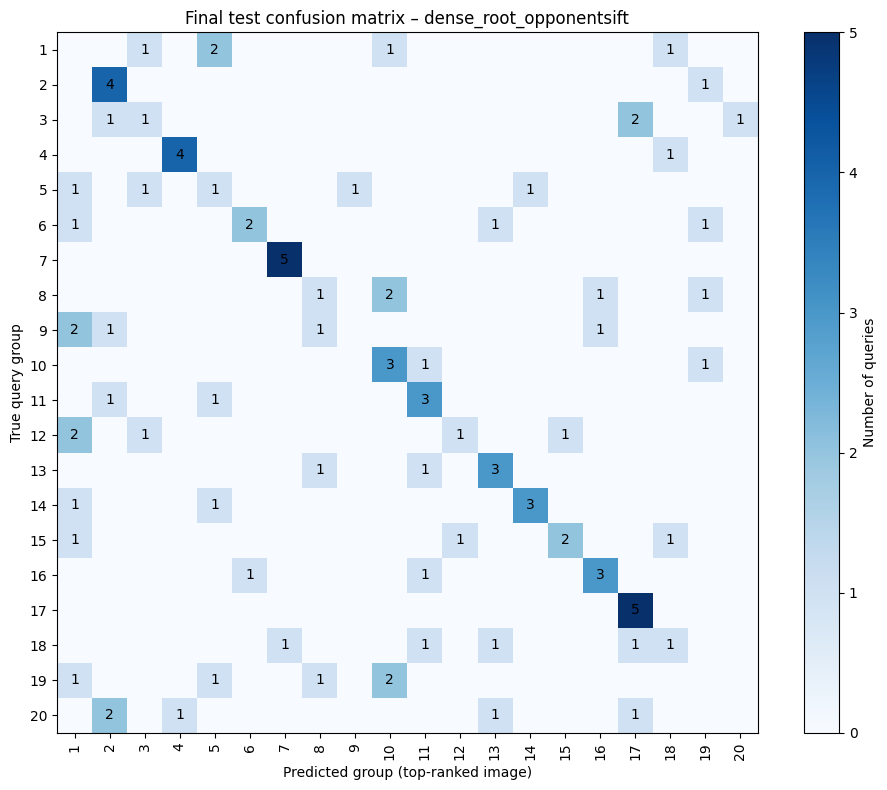

In [ ]:
groups = sorted(set(gallery_groups.tolist()))
group_index = {g: i for i, g in enumerate(groups)}
confusion = np.zeros((len(groups), len(groups)), dtype=int)
for row in query_rows:
    confusion[group_index[row["category"]], group_index[row["top1_category"]]] += 1

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(confusion, cmap="Blues")
ax.set(
    title=f"Final test confusion matrix – {CORE_CONFIG}",
    xlabel="Predicted group (top-ranked image)",
    ylabel="True query group",
    xticks=np.arange(len(groups)), yticks=np.arange(len(groups)),
)
ax.set_xticklabels(groups, rotation=90)
ax.set_yticklabels(groups)
for i in range(len(groups)):
    for j in range(len(groups)):
        if confusion[i, j]:
            ax.text(j, i, str(confusion[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax, label="Number of queries")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "stage10_test_confusion_matrix.png", dpi=180)
plt.show()

with (RESULTS_DIR / "stage10_test_confusion_matrix.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["true/predicted"] + groups)
    for group, values in zip(groups, confusion):
        writer.writerow([group] + values.tolist())

## 5. Four representative ranked retrieval examples

In [ ]:
ap_values = np.asarray([r["AP"] for r in query_rows])
wrong = [i for i, r in enumerate(query_rows) if r["category"] != r["top1_category"]]
indices = [int(np.argmax(ap_values)), int(np.argmin(ap_values)),
           int(np.argsort(ap_values)[len(ap_values) // 2])]
if wrong:
    indices.append(max(wrong, key=lambda i: ap_values[i]))

# Keep four distinct examples.
example_indices = []
for i in indices + list(np.argsort(ap_values)):
    if int(i) not in example_indices:
        example_indices.append(int(i))
    if len(example_indices) == 4:
        break

for i in example_indices:
    query = test[i]
    ranked = np.argsort(-similarity[i], kind="stable")[:8]
    fig, axes = plt.subplots(1, 9, figsize=(20, 3))
    axes[0].imshow(read_rgb(query.path))
    axes[0].set_title(f"QUERY\nGroup {query.category}", fontsize=9)
    axes[0].axis("off")
    for rank, j in enumerate(ranked, start=1):
        record = gallery[int(j)]
        axes[rank].imshow(read_rgb(record.path))
        axes[rank].set_title(
            f"#{rank} Group {record.category}\n"
            f"{'Relevant' if record.category == query.category else 'Other'}",
            fontsize=8,
        )
        axes[rank].axis("off")
    fig.suptitle(
        f"{query.filename} | AP={query_rows[i]['AP']:.3f} | "
        f"P@10={query_rows[i]['P@10']:.2f}", fontsize=11
    )
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"stage10_example_{i:03d}.png", dpi=150)
    plt.show()

print("\nStage 10 test evaluation complete. Do not use these results to retune the method.")

Output hidden; open in https://colab.research.google.com to view.

In [3]:

from cvpr.baseline import global_rgb_histogram
from cvpr.retrieval import compute_descriptors, euclidean_distances
from cvpr.evaluation import evaluate_retrieval

g_feat = compute_descriptors(gallery, global_rgb_histogram)
t_feat = compute_descriptors(test, global_rgb_histogram)
summary, rows = evaluate_retrieval(test, t_feat, gallery, g_feat, distance_fn=euclidean_distances, k=10)
print(f"Baseline TEST mAP: {summary['mAP']:.4f} | mean P@10: {summary['mean_P@10']:.4f}")

Baseline TEST mAP: 0.1740 | mean P@10: 0.2220
